## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача - распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [1]:

import requests

URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates'

headers = {
    'User-Agent': 'Mozilla/5.0',
    'Accept': 'application/json',
}

limit = 1000

response = requests.get(
    URL_LAUREATES,
    params={'limit': limit, 'offset': 0},
    headers=headers,
    timeout=30,
)
response.raise_for_status()

laureates = response.json()
total_count = laureates['meta']['count']

while len(laureates['laureates']) < total_count:
    offset = len(laureates['laureates'])

    response = requests.get(
        URL_LAUREATES,
        params={'limit': limit, 'offset': offset},
        headers=headers,
        timeout=30,
    )
    response.raise_for_status()

    page = response.json()
    new_laureates = page['laureates']

    if not new_laureates:
        break

    laureates['laureates'].extend(new_laureates)

print('Всего в API:', total_count)
print('Загружено:', len(laureates['laureates']))


Всего в API: 1028
Загружено: 1028


In [2]:

from laureates_configs import process_persons, process_orgs


def get_laureate_data(laureate: dict) -> dict:
    """Обрабатывает данные лауреата в зависимости от его типа."""
    if 'knownName' in laureate:
        result = process_persons(laureate)
        result['type_'] = 'person'
    else:
        result = process_orgs(laureate)
        result['type_'] = 'org'

    return result


laureates_data = [
    get_laureate_data(laureate)
    for laureate in laureates['laureates']
]

print('Обработано записей:', len(laureates_data))


Обработано записей: 1028


## Технический анализ данных

На этом этапе проверим полноту и целостность собранного датасета:
количество записей, пропущенные значения, диапазон идентификаторов,
повторяющиеся и пропущенные ID.

### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

In [3]:
from collections import Counter
from dataset_helpers import count_missing_values, find_id_gaps


# 1. Количество записей
total_records = len(laureates_data)

print('Всего записей:', total_records)


# 2. Пропущенные значения
missing_counts = count_missing_values(laureates_data)

missing_share = {
    field: round(count / total_records * 100, 2)
    for field, count in missing_counts.items()
}

print('\nКоличество пропусков:')
print(missing_counts)

print('\nДоля пропусков (%):')
print(missing_share)


# 3. Минимальный и максимальный ID
min_id_record = min(laureates_data, key=lambda item: item['id'])
max_id_record = max(laureates_data, key=lambda item: item['id'])

for record in [min_id_record, max_id_record]:
    award_years = [
        prize['award_year']
        for prize in record['prizes_relevant']
        if prize.get('award_year') is not None
    ]

    print(
        f"\nID: {record['id']}, "
        f"имя: {record['name']}, "
        f"годы награждения: {award_years}"
    )


# 4. Повторяющиеся ID
id_counts = Counter(item['id'] for item in laureates_data)

duplicate_ids = {
    id_: count
    for id_, count in id_counts.items()
    if count > 1
}

print('\nПовторяющиеся ID:', duplicate_ids)


# 5. Пропущенные ID
id_gaps = find_id_gaps(laureates_data)

print('\nКоличество разрывов ID:', len(id_gaps))
print('Первые 20 разрывов:', id_gaps[:20])


Всего записей: 1028

Количество пропусков:
{'birth_year': 28, 'country_birth': 31, 'country_founded': 1004, 'country_now': 7, 'founded_year': 1001, 'gender': 28, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}

Доля пропусков (%):
{'birth_year': 2.72, 'country_birth': 3.02, 'country_founded': 97.67, 'country_now': 0.68, 'founded_year': 97.37, 'gender': 2.72, 'id': 0.0, 'name': 0.0, 'prizes_relevant': 0.0, 'type_': 0.0}

ID: 1, имя: Wilhelm Conrad Röntgen, годы награждения: [1901]

ID: 1070, имя: Michael Woodford, годы награждения: [2026]

Повторяющиеся ID: {}

Количество разрывов ID: 24
Первые 20 разрывов: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (783, 786), (787, 789)]


### Выводы по техническому анализу

В датасете содержится 1028 записей о Нобелевских лауреатах. Основные идентификационные поля заполнены полностью, повторяющихся ID не обнаружено.

Часть полей содержит пропуски. При этом большинство пропусков в полях, связанных с рождением или основанием, обусловлено различиями между людьми и организациями. Для оценки реальной полноты таких данных необходимо рассматривать эти группы отдельно.

Минимальный ID равен 1 (Wilhelm Conrad Röntgen, премия 1901 года), максимальный - 1070 (Michael Woodford, премия 2026 года). Обнаружено 24 разрыва между соседними ID. Сами по себе эти разрывы не свидетельствуют о потере данных, поскольку идентификаторы не обязаны идти последовательно.

----------

## Основной анализ

### 1. Распределение лауреатов по странам

Определим пять стран с наибольшим количеством лауреатов. Для анализа используем страну рождения человека (`country_birth`). Организации и записи с неизвестной страной рождения исключим.

Затем сравним распределение лауреатов по категориям Нобелевской премии.

In [4]:

from dataset_helpers import filter_data, group_by_attributes
from aggregations import count_records
from aggregations import top_n

# Оставляем людей с известной страной рождения
persons = filter_data(
    laureates_data,
    lambda item: item['type_'] == 'person'
    and item['country_birth'] is not None
)

# Группируем лауреатов по странам
country_groups = group_by_attributes(persons, ['country_birth'])

# Считаем количество лауреатов в каждой стране
country_counts = [
    {'country': country[0], 'count': count_records(records)}
    for country, records in country_groups.items()
]


top_countries = top_n(country_counts, 'count', 5)


print('Топ-5 стран по количеству лауреатов:')

for item in top_countries:
    print(f"{item['country']}: {item['count']}")


Топ-5 стран по количеству лауреатов:
USA: 299
United Kingdom: 94
Germany: 82
France: 61
Japan: 31


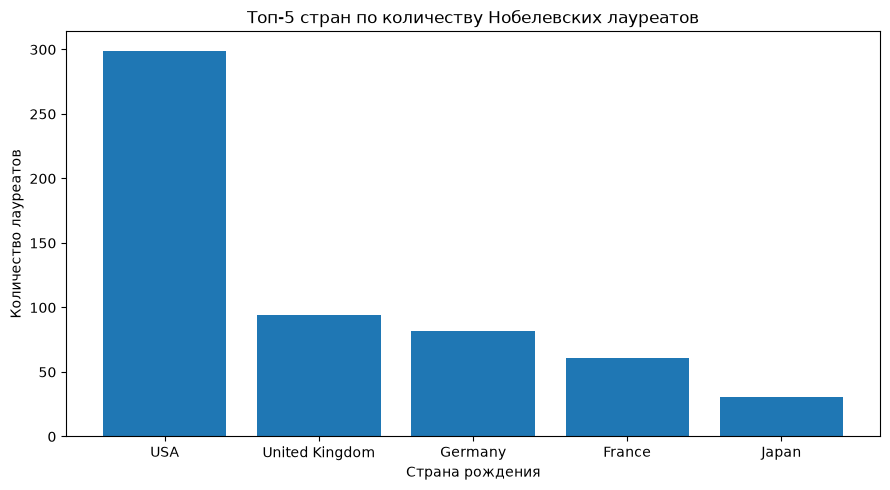

In [5]:

import matplotlib.pyplot as plt

countries = [item['country'] for item in top_countries]
counts = [item['count'] for item in top_countries]

plt.figure(figsize=(9, 5))
plt.bar(countries, counts)

plt.title('Топ-5 стран по количеству Нобелевских лауреатов')
plt.xlabel('Страна рождения')
plt.ylabel('Количество лауреатов')

plt.tight_layout()
plt.show()


### Распределение стран по категориям Нобелевской премии

Рассмотрим географическое распределение лауреатов отдельно по категориям премий. Это позволит определить, какие страны наиболее представлены в каждой научной и гуманитарной области.

Каждый лауреат учитывается один раз внутри каждой категории, даже если он получал несколько премий одной категории.

In [6]:

# Формируем записи с уникальными сочетаниями страны и категории
country_category_data = []

for person in persons:
    categories = {
        prize['category_en']
        for prize in person['prizes_relevant']
        if prize.get('category_en') is not None
    }

    for category in categories:
        country_category_data.append({
            'country': person['country_birth'],
            'category': category,
            'id': person['id'],
        })


# Группируем по категории и стране
category_groups = group_by_attributes(
    country_category_data,
    ['category', 'country'],
)

category_counts = [
    {
        'category': category,
        'country': country,
        'count': count_records(records),
    }
    for (category, country), records in category_groups.items()
]


# Выводим топ-5 стран в каждой категории
categories = sorted({
    item['category'] for item in category_counts
})

for category in categories:
    top_countries_category = sorted(
        [
            item for item in category_counts
            if item['category'] == category
        ],
        key=lambda item: (-item['count'], item['country']),
    )[:5]

    print(f'\n{category}:')

    for item in top_countries_category:
        print(f"  {item['country']}: {item['count']}")



Chemistry:
  USA: 59
  United Kingdom: 26
  Germany: 24
  France: 12
  Japan: 9

Economic Sciences:
  USA: 56
  United Kingdom: 7
  Canada: 5
  France: 5
  the Netherlands: 4

Literature:
  France: 12
  USA: 10
  Sweden: 7
  United Kingdom: 6
  Italy: 5

Peace:
  USA: 19
  France: 9
  Germany: 6
  Sweden: 5
  United Kingdom: 5

Physics:
  USA: 71
  United Kingdom: 25
  Germany: 24
  Japan: 12
  France: 11

Physiology or Medicine:
  USA: 85
  United Kingdom: 25
  Germany: 22
  France: 12
  Sweden: 8


### Выводы по распределению лауреатов по странам

США занимают первое место по общему количеству лауреатов - 299 человек. Далее следуют Великобритания (94), Германия (82), Франция (61) и Япония (31).

При рассмотрении отдельных категорий США также лидируют в пяти из шести направлений. Особенно заметно их преимущество в экономике, физике и физиологии или медицине.

Исключением является литература, где первое место занимает Франция с 12 лауреатами, опережая США с 10 лауреатами.

Таким образом, распределение лауреатов по странам неоднородно: США имеют наиболее сильное представительство в большинстве категорий, тогда как в литературе лидирует Франция.

## 2. Возраст получения первой Нобелевской премии

На этом этапе исследуем возраст лауреатов на момент получения первой Нобелевской премии.

Для расчёта используем год рождения и год первой награды. Поскольку точные даты рождения и вручения премий не учитываются, возраст рассчитывается приблизительно.

Рассмотрим общие характеристики возраста, различия между категориями премий и изменения показателя по десятилетиям.

In [7]:

# Отбираем всех лауреатов-людей
all_persons = filter_data(
    laureates_data,
    lambda item: item['type_'] == 'person'
)

# Формируем данные о возрасте первой премии
age_data = []

for person in all_persons:
    birth_year = person.get('birth_year')
    prizes = person.get('prizes_relevant') or []

    award_years = [
        prize['award_year']
        for prize in prizes
        if prize.get('award_year') is not None
    ]

    if birth_year is None or not award_years:
        continue

    first_award_year = min(award_years)

    age_data.append({
        'id': person['id'],
        'name': person['name'],
        'birth_year': birth_year,
        'first_award_year': first_award_year,
        'age': first_award_year - birth_year,
    })

print('Всего лауреатов-людей:', len(all_persons))
print('Записей для анализа возраста:', len(age_data))


Всего лауреатов-людей: 1000
Записей для анализа возраста: 1000


In [8]:

from dataset_helpers import aggregate_data
from aggregations import (
    count_records,
    calculate_mean,
    calculate_median,
    calculate_max,
)

age_summary = aggregate_data(
    age_data,
    {
        'count': count_records,
        'mean_age': lambda data: calculate_mean(data, 'age'),
        'median_age': lambda data: calculate_median(data, 'age'),
        'max_age': lambda data: calculate_max(data, 'age'),
    },
)

min_age = min(item['age'] for item in age_data)

print('Количество лауреатов:', age_summary['count'])
print(f"Средний возраст: {age_summary['mean_age']:.2f}")
print(f"Медианный возраст: {age_summary['median_age']}")
print(f"Минимальный возраст: {min_age}")
print(f"Максимальный возраст: {age_summary['max_age']}")


Количество лауреатов: 1000
Средний возраст: 60.61
Медианный возраст: 61.0
Минимальный возраст: 17
Максимальный возраст: 97


### Возраст получения первой премии по категориям

Сравним возраст получения первой Нобелевской премии между категориями. Для каждой категории определим средний и медианный возраст, а также минимальное и максимальное значения.

Если лауреат получал несколько премий в одной категории, будем учитывать год его первой награды в этой категории.

In [9]:

# Формируем данные о возрасте первой премии в каждой категории

age_by_category = []

for person in all_persons:
    birth_year = person.get('birth_year')

    if birth_year is None:
        continue

    category_years = {}

    for prize in person['prizes_relevant']:
        category = prize.get('category_en')
        award_year = prize.get('award_year')

        if category is None or award_year is None:
            continue

        if (
            category not in category_years
            or award_year < category_years[category]
        ):
            category_years[category] = award_year

    for category, award_year in category_years.items():
        age_by_category.append({
            'id': person['id'],
            'category': category,
            'age': award_year - birth_year,
        })


# Группируем данные по категориям
category_age_groups = group_by_attributes(
    age_by_category,
    ['category'],
)


# Рассчитываем статистики
for (category,), records in sorted(category_age_groups.items()):
    result = aggregate_data(
        records,
        {
            'count': count_records,
            'mean': lambda data: calculate_mean(data, 'age'),
            'median': lambda data: calculate_median(data, 'age'),
            'max': lambda data: calculate_max(data, 'age'),
            'min': lambda data: min(item['age'] for item in data),
        },
    )

    print(f'\n{category}:')
    print(f"  Лауреатов: {result['count']}")
    print(f"  Средний возраст: {result['mean']:.2f}")
    print(f"  Медианный возраст: {result['median']}")
    print(f"  Минимальный возраст: {result['min']}")
    print(f"  Максимальный возраст: {result['max']}")



Chemistry:
  Лауреатов: 200
  Средний возраст: 59.35
  Медианный возраст: 58.0
  Минимальный возраст: 35
  Максимальный возраст: 97

Economic Sciences:
  Лауреатов: 101
  Средний возраст: 67.21
  Медианный возраст: 67
  Минимальный возраст: 47
  Максимальный возраст: 90

Literature:
  Лауреатов: 123
  Средний возраст: 65.04
  Медианный возраст: 67
  Минимальный возраст: 42
  Максимальный возраст: 88

Peace:
  Лауреатов: 113
  Средний возраст: 60.97
  Медианный возраст: 62
  Минимальный возраст: 17
  Максимальный возраст: 87

Physics:
  Лауреатов: 230
  Средний возраст: 57.79
  Медианный возраст: 56.0
  Минимальный возраст: 25
  Максимальный возраст: 96

Physiology or Medicine:
  Лауреатов: 235
  Средний возраст: 59.02
  Медианный возраст: 58
  Минимальный возраст: 32
  Максимальный возраст: 87


### Изменение возраста получения первой премии по десятилетиям

Исследуем динамику возраста получения первой Нобелевской премии во времени. Для этого разделим лауреатов на группы в зависимости от десятилетия получения первой награды и рассчитаем количество лауреатов, средний и медианный возраст в каждой группе.

In [10]:

# Добавляем десятилетие первой награды
age_by_decade = []

for person in age_data:
    decade = person['first_award_year'] // 10 * 10

    age_by_decade.append({
        'id': person['id'],
        'decade': decade,
        'age': person['age'],
    })


# Группируем по десятилетиям
decade_groups = group_by_attributes(
    age_by_decade,
    ['decade'],
)


# Рассчитываем статистики
for (decade,), records in sorted(decade_groups.items()):
    result = aggregate_data(
        records,
        {
            'count': count_records,
            'mean': lambda data: calculate_mean(data, 'age'),
            'median': lambda data: calculate_median(data, 'age'),
        },
    )

    print(f'\n{decade}-е годы:')
    print(f"  Лауреатов: {result['count']}")
    print(f"  Средний возраст: {result['mean']:.2f}")
    print(f"  Медианный возраст: {result['median']}")



1900-е годы:
  Лауреатов: 56
  Средний возраст: 57.84
  Медианный возраст: 58.0

1910-е годы:
  Лауреатов: 37
  Средний возраст: 53.08
  Медианный возраст: 50

1920-е годы:
  Лауреатов: 54
  Средний возраст: 54.98
  Медианный возраст: 56.0

1930-е годы:
  Лауреатов: 55
  Средний возраст: 51.62
  Медианный возраст: 49

1940-е годы:
  Лауреатов: 40
  Средний возраст: 58.02
  Медианный возраст: 56.0

1950-е годы:
  Лауреатов: 71
  Средний возраст: 54.32
  Медианный возраст: 54

1960-е годы:
  Лауреатов: 74
  Средний возраст: 56.45
  Медианный возраст: 57.0

1970-е годы:
  Лауреатов: 102
  Средний возраст: 59.34
  Медианный возраст: 59.0

1980-е годы:
  Лауреатов: 93
  Средний возраст: 60.54
  Медианный возраст: 60

1990-е годы:
  Лауреатов: 101
  Средний возраст: 62.14
  Медианный возраст: 62

2000-е годы:
  Лауреатов: 119
  Средний возраст: 65.87
  Медианный возраст: 64

2010-е годы:
  Лауреатов: 117
  Средний возраст: 66.85
  Медианный возраст: 69

2020-е годы:
  Лауреатов: 81
  Средни

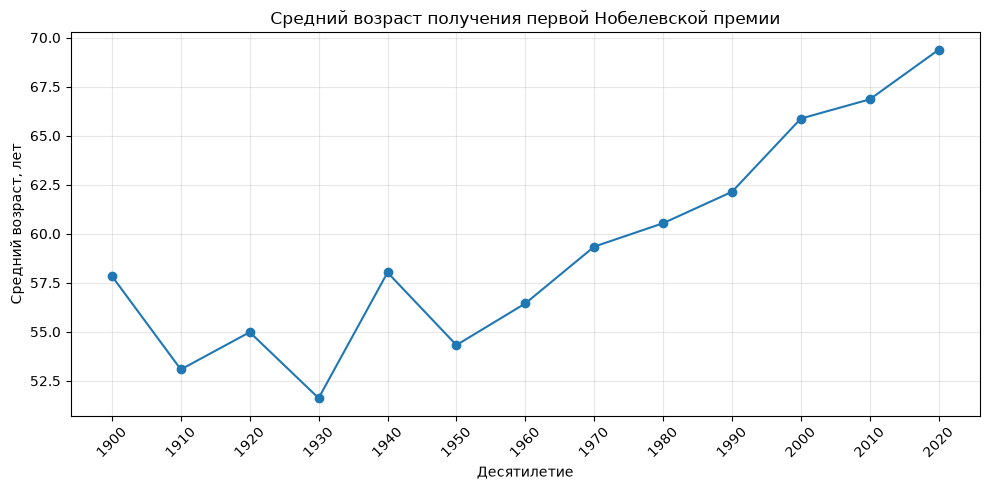

In [11]:

decades = []
mean_ages = []

for (decade,), records in sorted(decade_groups.items()):
    decades.append(decade)
    mean_ages.append(calculate_mean(records, 'age'))

plt.figure(figsize=(10, 5))
plt.plot(decades, mean_ages, marker='o')

plt.title('Средний возраст получения первой Нобелевской премии')
plt.xlabel('Десятилетие')
plt.ylabel('Средний возраст, лет')
plt.xticks(decades, rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Выводы по возрасту получения первой Нобелевской премии

Средний возраст получения первой Нобелевской премии в общей выборке составляет 60,61 года, медианный - 61 год. Минимальный возраст - 17 лет, максимальный - 97 лет.

Наиболее высокий средний возраст наблюдается в экономике (67,21 года), наиболее низкий - в физике (57,79 года). Разница между категориями составляет около 9,4 года.

При анализе динамики по десятилетиям наблюдается увеличение возраста награждения. В 1930-х средний возраст составлял 51,62 года, а в 2020-х достиг 69,38 года.

Таким образом, возраст получения первой премии различается в зависимости от категории, а в рассматриваемом периоде прослеживается тенденция к его увеличению. При этом данные за 2020-е охватывают только часть десятилетия.

## 3. Гендерное распределение лауреатов

Исследуем гендерный состав Нобелевских лауреатов. Сначала рассмотрим общее соотношение мужчин и женщин, затем сравним представленность женщин в разных категориях премий и проследим изменения по десятилетиям.

Организации в анализ не включаем. Записи с неизвестным значением пола будем учитывать отдельно.

In [12]:

from collections import Counter

# Общее гендерное распределение
gender_counts = Counter(
    person.get('gender') or 'unknown'
    for person in all_persons
)

known_gender_count = (
    gender_counts['male'] + gender_counts['female']
)

print('Гендерное распределение:')

for gender, count in sorted(gender_counts.items()):
    print(f'{gender}: {count}')

print(
    '\nДоля женщин среди лауреатов с известным полом:',
    round(gender_counts['female'] / known_gender_count * 100, 2),
    '%'
)


Гендерное распределение:
female: 69
male: 931

Доля женщин среди лауреатов с известным полом: 6.9 %


In [13]:

# Формируем уникальные сочетания лауреатов и категорий
gender_category_data = []

for person in all_persons:
    categories = {
        prize['category_en']
        for prize in person['prizes_relevant']
        if prize.get('category_en') is not None
    }

    for category in categories:
        gender_category_data.append({
            'category': category,
            'gender': person.get('gender') or 'unknown',
        })


# Группируем по категории и полу
gender_category_groups = group_by_attributes(
    gender_category_data,
    ['category', 'gender'],
)

categories = sorted({
    item['category'] for item in gender_category_data
})

for category in categories:
    counts = {
        gender: count_records(records)
        for (group_category, gender), records
        in gender_category_groups.items()
        if group_category == category
    }

    known = counts.get('male', 0) + counts.get('female', 0)
    female_share = counts.get('female', 0) / known * 100

    print(f'\n{category}:')
    print(f"  Мужчины: {counts.get('male', 0)}")
    print(f"  Женщины: {counts.get('female', 0)}")
    print(f"  Неизвестно: {counts.get('unknown', 0)}")
    print(f"  Доля женщин: {female_share:.2f}%")



Chemistry:
  Мужчины: 192
  Женщины: 8
  Неизвестно: 0
  Доля женщин: 4.00%

Economic Sciences:
  Мужчины: 98
  Женщины: 3
  Неизвестно: 0
  Доля женщин: 2.97%

Literature:
  Мужчины: 104
  Женщины: 19
  Неизвестно: 0
  Доля женщин: 15.45%

Peace:
  Мужчины: 92
  Женщины: 21
  Неизвестно: 0
  Доля женщин: 18.58%

Physics:
  Мужчины: 225
  Женщины: 5
  Неизвестно: 0
  Доля женщин: 2.17%

Physiology or Medicine:
  Мужчины: 221
  Женщины: 14
  Неизвестно: 0
  Доля женщин: 5.96%


In [14]:

# Формируем данные о поле и десятилетии первой премии
gender_by_decade = []

for person in all_persons:
    award_years = [
        prize['award_year']
        for prize in person['prizes_relevant']
        if prize.get('award_year') is not None
    ]

    if not award_years:
        continue

    first_award_year = min(award_years)
    decade = first_award_year // 10 * 10

    gender_by_decade.append({
        'decade': decade,
        'gender': person.get('gender') or 'unknown',
    })


# Группируем по десятилетиям и полу
decade_gender_groups = group_by_attributes(
    gender_by_decade,
    ['decade', 'gender'],
)

decades = sorted({
    item['decade'] for item in gender_by_decade
})

for decade in decades:
    counts = {
        gender: count_records(records)
        for (group_decade, gender), records
        in decade_gender_groups.items()
        if group_decade == decade
    }

    known = counts.get('male', 0) + counts.get('female', 0)
    female_share = counts.get('female', 0) / known * 100

    print(f'\n{decade}-е годы:')
    print(f"  Мужчины: {counts.get('male', 0)}")
    print(f"  Женщины: {counts.get('female', 0)}")
    print(f"  Доля женщин: {female_share:.2f}%")



1900-е годы:
  Мужчины: 53
  Женщины: 3
  Доля женщин: 5.36%

1910-е годы:
  Мужчины: 37
  Женщины: 0
  Доля женщин: 0.00%

1920-е годы:
  Мужчины: 52
  Женщины: 2
  Доля женщин: 3.70%

1930-е годы:
  Мужчины: 52
  Женщины: 3
  Доля женщин: 5.45%

1940-е годы:
  Мужчины: 37
  Женщины: 3
  Доля женщин: 7.50%

1950-е годы:
  Мужчины: 71
  Женщины: 0
  Доля женщин: 0.00%

1960-е годы:
  Мужчины: 71
  Женщины: 3
  Доля женщин: 4.05%

1970-е годы:
  Мужчины: 98
  Женщины: 4
  Доля женщин: 3.92%

1980-е годы:
  Мужчины: 89
  Женщины: 4
  Доля женщин: 4.30%

1990-е годы:
  Мужчины: 94
  Женщины: 7
  Доля женщин: 6.93%

2000-е годы:
  Мужчины: 108
  Женщины: 11
  Доля женщин: 9.24%

2010-е годы:
  Мужчины: 104
  Женщины: 13
  Доля женщин: 11.11%

2020-е годы:
  Мужчины: 65
  Женщины: 16
  Доля женщин: 19.75%


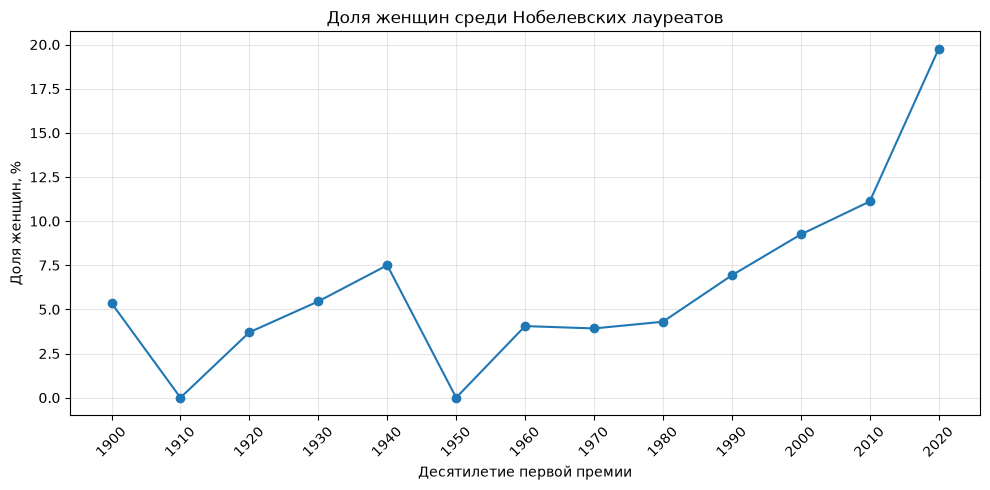

In [15]:

female_shares = []

for decade in decades:
    counts = {
        gender: count_records(records)
        for (group_decade, gender), records
        in decade_gender_groups.items()
        if group_decade == decade
    }

    female = counts.get('female', 0)
    male = counts.get('male', 0)
    share = female / (female + male) * 100

    female_shares.append(share)

plt.figure(figsize=(10, 5))
plt.plot(decades, female_shares, marker='o')

plt.title('Доля женщин среди Нобелевских лауреатов')
plt.xlabel('Десятилетие первой премии')
plt.ylabel('Доля женщин, %')
plt.xticks(decades, rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Выводы по гендерному распределению лауреатов

В общей выборке из 1000 лауреатов мужчины составляют 93,1%, женщины - 6,9%. Таким образом, исторически среди Нобелевских лауреатов преобладают мужчины.

Наибольшая доля женщин наблюдается в категориях «Премия мира» (18,58%) и «Литература» (15,45%). Наименьшая - в физике (2,17%) и экономике (2,97%).

При анализе динамики по десятилетиям заметно увеличение представленности женщин. Если в первой половине XX века их доля преимущественно составляла менее 8%, то в 2000-х она достигла 9,24%, в 2010-х - 11,11%, а в 2020-х - 19,75%.

Таким образом, несмотря на сохраняющееся гендерное неравенство, в последние десятилетия наблюдается увеличение доли женщин среди Нобелевских лауреатов.

## Бонусное задание. Анализ текстов мотиваций

Исследуем тексты, которыми обосновывалось вручение Нобелевских премий. Сначала определим 50 самых частых слов, затем исключим общеупотребительные английские слова и сравним наиболее популярные слова по категориям премий.

Для анализа используем английские тексты мотиваций. Слова приводим к нижнему регистру и удаляем знаки препинания.

In [16]:

import re
from collections import Counter


# Собираем тексты мотиваций
prizes = [
    prize
    for laureate in laureates_data
    for prize in laureate['prizes_relevant']
    if prize.get('motivation')
]

def get_words(text: str) -> list[str]:
    """Выделяет английские слова из текста."""
    return re.findall(r"[a-z]+", text.lower())


all_words = [
    word
    for prize in prizes
    for word in get_words(prize['motivation'])
]

word_counts = Counter(all_words)

print('Количество текстов:', len(prizes))
print('\nТоп-50 слов:')

for word, count in word_counts.most_common(50):
    print(f'{word}: {count}')


Количество текстов: 1036

Топ-50 слов:
of: 1291
the: 1248
for: 1149
and: 670
in: 449
their: 394
his: 376
to: 278
discovery: 211
discoveries: 172
a: 151
concerning: 124
development: 110
work: 106
on: 101
with: 99
which: 99
by: 82
theory: 74
contributions: 61
has: 60
structure: 58
that: 55
peace: 53
recognition: 48
economic: 45
human: 44
chemical: 43
as: 42
analysis: 42
new: 41
its: 39
synthesis: 38
pioneering: 38
an: 38
fundamental: 37
efforts: 36
between: 34
chemistry: 34
he: 34
her: 32
studies: 31
through: 31
international: 30
method: 30
especially: 29
methods: 29
having: 28
role: 27
research: 26


In [17]:

from stopwords import STOPWORDS

filtered_words = [
    word for word in all_words
    if word not in STOPWORDS
]

filtered_counts = Counter(filtered_words)

print('Топ-50 слов после удаления стоп-слов:')

for word, count in filtered_counts.most_common(50):
    print(f'{word}: {count}')


Топ-50 слов после удаления стоп-слов:
discovery: 211
discoveries: 172
concerning: 124
development: 110
work: 106
theory: 74
contributions: 61
structure: 58
peace: 53
recognition: 48
economic: 45
human: 44
chemical: 43
analysis: 42
new: 41
synthesis: 38
pioneering: 38
fundamental: 37
efforts: 36
between: 34
chemistry: 34
studies: 31
through: 31
international: 30
method: 30
especially: 29
methods: 29
having: 28
role: 27
research: 26
quantum: 26
cell: 26
nuclear: 26
system: 26
contribution: 26
s: 25
into: 24
investigations: 24
rights: 24
organic: 23
life: 23
mechanism: 23
high: 23
genetic: 22
reactions: 21
our: 21
light: 20
invention: 20
i: 20
important: 19


In [18]:

category_words = {}

for prize in prizes:
    category = prize.get('category_en')
    if category is None:
        continue

    words = [
        word for word in get_words(prize['motivation'])
        if word not in STOPWORDS
    ]

    category_words.setdefault(category, []).extend(words)


top_words_by_category = {}

for category, words in sorted(category_words.items()):
    top_10 = Counter(words).most_common(10)
    top_words_by_category[category] = {word for word, _ in top_10}

    print(f'\n{category}:')
    print(top_10)


print('\nОбщие слова между категориями:')

categories = sorted(top_words_by_category)

for i, category_1 in enumerate(categories):
    for category_2 in categories[i + 1:]:
        common = (
            top_words_by_category[category_1]
            & top_words_by_category[category_2]
        )
        print(f'{category_1} / {category_2}: {sorted(common)}')



Chemistry:
[('development', 52), ('discovery', 36), ('chemistry', 33), ('chemical', 31), ('synthesis', 28), ('work', 26), ('structure', 23), ('organic', 23), ('studies', 20), ('contributions', 17)]

Economic Sciences:
[('theory', 43), ('economic', 41), ('analysis', 35), ('contributions', 18), ('having', 18), ('pioneering', 15), ('research', 13), ('markets', 10), ('financial', 8), ('empirical', 8)]

Literature:
[('human', 19), ('life', 19), ('poetry', 18), ('poetic', 17), ('i', 16), ('art', 16), ('s', 14), ('great', 12), ('power', 11), ('narrative', 11)]

Peace:
[('peace', 53), ('efforts', 36), ('work', 32), ('international', 26), ('rights', 23), ('between', 19), ('war', 19), ('peaceful', 17), ('struggle', 16), ('human', 16)]

Physics:
[('discovery', 100), ('development', 30), ('discoveries', 27), ('theory', 25), ('contributions', 23), ('quantum', 22), ('fundamental', 21), ('structure', 20), ('work', 20), ('physics', 19)]

Physiology or Medicine:
[('discoveries', 138), ('concerning', 9

### Выводы по анализу мотиваций

В результате обработки получено 1036 текстов мотиваций. Первоначальный анализ показал, что наиболее частыми словами являются общеупотребительные английские слова: *of*, *the*, *for*, *and*, *in*.

После удаления стоп-слов наиболее распространёнными стали *discovery*, *discoveries*, *development*, *work* и *theory*. Это отражает важную роль научных открытий, исследований и разработок в формулировках Нобелевского комитета.

Сравнение категорий выявило тематические различия:

- **Химия:** *chemistry*, *chemical*, *synthesis*, *organic*.
- **Экономика:** *theory*, *economic*, *analysis*, *markets*.
- **Литература:** *human*, *life*, *poetry*, *art*.
- **Премия мира:** *peace*, *efforts*, *international*, *rights*.
- **Физика:** *discovery*, *theory*, *quantum*, *fundamental*.
- **Медицина:** *discoveries*, *cell*, *genetic*, *mechanisms*.

Наиболее заметное пересечение топ-10 наблюдается между химией и физикой, а также между физикой и медициной. Для литературы характерен более самостоятельный словарь, связанный с человеческой жизнью и художественным творчеством.

Таким образом, частотный анализ позволяет выявить как общие формулировки Нобелевских мотиваций, так и специфическую лексику отдельных катег